# Environment Setup

## Import libraries

In [1]:
import os
import re
import random
import unicodedata
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from sklearn.model_selection import train_test_split

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Libraries imported successfully!")
print("PyTorch version:", torch.__version__)


Libraries imported successfully!
PyTorch version: 2.11.0+cu130


## GPU configuration

In [2]:

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("GPU unavailable. Check Kaggle Accelerator settings.")


Device: cuda
GPU: Tesla T4
CUDA version: 13.0


# Dataset Exploration (EDA)

# Load dataset files

In [3]:
file_path = "/kaggle/input/datasets/sayedshaun/english-to-bengali-for-machine-translation/english_to_bangla.csv"

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (39065, 2)


,en,bn
0,a child in a pink dress is climbing up a set o...,একটি গোলাপী জামা পরা বাচ্চা মেয়ে একটি বাড়ির প্...
1,a girl going into a wooden building .,একটি মেয়ে শিশু একটি কাঠের বাড়িতে ঢুকছে
2,a little girl climbing into a wooden playhouse .,একটি বাচ্চা তার কাঠের খেলাঘরে উঠছে ।
3,a little girl climbing the stairs to her playh...,ছোট মেয়েটি তার খেলার ঘরের সিড়ি বেয়ে উঠছে
4,a little girl in a pink dress going into a woo...,গোলাপি জামা পড়া ছোট একটি মেয়ে একটি কাঠের তৈরি...


## Basic EDA

In [4]:

print("Columns:", df.columns.tolist())
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())


Columns: ['en', 'bn']

Missing Values:
 en    0
bn    0
dtype: int64

Duplicate Rows: 0


# Text Preprocessing

## Text Cleaning

In [5]:
def clean_text(text, lowercase=False):
    text = unicodedata.normalize("NFC", text)
    text = re.sub(r"\s+", " ", text).strip()

    if lowercase:
        text = text.lower()

    return text

df["en"] = df["en"].apply(lambda x: clean_text(x, lowercase=True))
df["bn"] = df["bn"].apply(clean_text)

display(df.head())


,en,bn
0,a child in a pink dress is climbing up a set o...,একটি গোলাপী জামা পরা বাচ্চা মেয়ে একটি বাড়ির ...
1,a girl going into a wooden building .,একটি মেয়ে শিশু একটি কাঠের বাড়িতে ঢুকছে
2,a little girl climbing into a wooden playhouse .,একটি বাচ্চা তার কাঠের খেলাঘরে উঠছে ।
3,a little girl climbing the stairs to her playh...,ছোট মেয়েটি তার খেলার ঘরের সিড়ি বেয়ে উঠছে
4,a little girl in a pink dress going into a woo...,গোলাপি জামা পড়া ছোট একটি মেয়ে একটি কাঠের তৈর...


## Tokenization & Length Filtering

In [6]:
# Tokenization
df["en_tokens"] = df["en"].str.split()
df["bn_tokens"] = df["bn"].str.split()

# Filter empty or overly long sentences
MAX_LEN = 30

df = df[
    df["en_tokens"].str.len().between(1, MAX_LEN) &
    df["bn_tokens"].str.len().between(1, MAX_LEN)
].reset_index(drop=True)

print("Dataset Shape After Preprocessing:", df.shape)

display(df[["en", "bn", "en_tokens", "bn_tokens"]].head())


Dataset Shape After Preprocessing: (39040, 4)


,en,bn,en_tokens,bn_tokens
0,a child in a pink dress is climbing up a set o...,একটি গোলাপী জামা পরা বাচ্চা মেয়ে একটি বাড়ির ...,"[a, child, in, a, pink, dress, is, climbing, u...","[একটি, গোলাপী, জামা, পরা, বাচ্চা, মেয়ে, একটি,..."
1,a girl going into a wooden building .,একটি মেয়ে শিশু একটি কাঠের বাড়িতে ঢুকছে,"[a, girl, going, into, a, wooden, building, .]","[একটি, মেয়ে, শিশু, একটি, কাঠের, বাড়িতে, ঢুকছে]"
2,a little girl climbing into a wooden playhouse .,একটি বাচ্চা তার কাঠের খেলাঘরে উঠছে ।,"[a, little, girl, climbing, into, a, wooden, p...","[একটি, বাচ্চা, তার, কাঠের, খেলাঘরে, উঠছে, ।]"
3,a little girl climbing the stairs to her playh...,ছোট মেয়েটি তার খেলার ঘরের সিড়ি বেয়ে উঠছে,"[a, little, girl, climbing, the, stairs, to, h...","[ছোট, মেয়েটি, তার, খেলার, ঘরের, সিড়ি, বেয়ে,..."
4,a little girl in a pink dress going into a woo...,গোলাপি জামা পড়া ছোট একটি মেয়ে একটি কাঠের তৈর...,"[a, little, girl, in, a, pink, dress, going, i...","[গোলাপি, জামা, পড়া, ছোট, একটি, মেয়ে, একটি, ক..."


# Train, Validation & Test Split

## Split Dataset

In [7]:
# First split: 80% training, 20% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=SEED
)

# Second split: 10% validation, 10% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=SEED
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))


Training samples: 31232
Validation samples: 3904
Testing samples: 3904


# Vocabulary Construction

## Build Vocabulary

In [8]:

SPECIAL_TOKENS = ["<pad>", "<unk>", "<sos>", "<eos>"]

PAD_IDX, UNK_IDX, SOS_IDX, EOS_IDX = range(4)

def build_vocab(sentences, min_freq=2):
    counter = Counter(
        token
        for sentence in sentences
        for token in sentence
    )

    vocab = SPECIAL_TOKENS + [
        token for token, freq in counter.most_common()
        if freq >= min_freq
    ]

    stoi = {token: idx for idx, token in enumerate(vocab)}
    itos = {idx: token for token, idx in stoi.items()}

    return stoi, itos

# Build vocabularies using training data only
en_stoi, en_itos = build_vocab(train_df["en_tokens"])
bn_stoi, bn_itos = build_vocab(train_df["bn_tokens"])

print("English Vocabulary Size:", len(en_stoi))
print("Bengali Vocabulary Size:", len(bn_stoi))


English Vocabulary Size: 4722
Bengali Vocabulary Size: 6945


## Convert Tokens to Indices

In [9]:
def numericalize(tokens, stoi):
    return [
        stoi.get(token, UNK_IDX)
        for token in tokens
    ]

# Example
en_tokens = train_df["en_tokens"].iloc[0]
bn_tokens = train_df["bn_tokens"].iloc[0]

print("English Tokens:", en_tokens)
print("English Indices:", numericalize(en_tokens, en_stoi))

print("\nBengali Tokens:", bn_tokens)
print("Bengali Indices:", numericalize(bn_tokens, bn_stoi))


English Tokens: ['a', 'little', 'girl', 'ends', 'up', 'at', 'the', 'bottom', 'of', 'the', 'slide', '.']
English Indices: [4, 42, 21, 1737, 55, 25, 7, 891, 14, 7, 185, 5]

Bengali Tokens: ['মেয়েটি', 'একটি', 'স্লাইডের', 'শেষ', 'মাথায়', 'বসে', 'আছে']
Bengali Indices: [84, 4, 739, 1323, 220, 19, 9]


# Custom Dataset & DataLoader

## Custom Dataset

In [10]:
class TranslationDataset(Dataset):
    def __init__(self, dataframe, en_stoi, bn_stoi):
        self.dataframe = dataframe
        self.en_stoi = en_stoi
        self.bn_stoi = bn_stoi

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        src = numericalize(row["en_tokens"], self.en_stoi)
        tgt = numericalize(row["bn_tokens"], self.bn_stoi)

        src = src + [EOS_IDX]
        tgt = [SOS_IDX] + tgt + [EOS_IDX]

        return (
            torch.tensor(src, dtype=torch.long),
            torch.tensor(tgt, dtype=torch.long)
        )


train_dataset = TranslationDataset(train_df, en_stoi, bn_stoi)
val_dataset = TranslationDataset(val_df, en_stoi, bn_stoi)
test_dataset = TranslationDataset(test_df, en_stoi, bn_stoi)


## Custom Collate Function & DataLoader

In [11]:
def collate_fn(batch):
    src_batch, tgt_batch = zip(*batch)

    src_batch = pad_sequence(
        src_batch, batch_first=True, padding_value=PAD_IDX
    )

    tgt_batch = pad_sequence(
        tgt_batch, batch_first=True, padding_value=PAD_IDX
    )

    return src_batch, tgt_batch


BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, collate_fn=collate_fn
)

src_batch, tgt_batch = next(iter(train_loader))

print("Source Batch Shape:", src_batch.shape)
print("Target Batch Shape:", tgt_batch.shape)
print("Training Batches:", len(train_loader))


Source Batch Shape: torch.Size([64, 27])
Target Batch Shape: torch.Size([64, 21])
Training Batches: 488


# Encoder Implementation

## Encoder Class

In [12]:
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

class Encoder(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=PAD_IDX
        )

        self.gru = nn.GRU(
            embed_dim,
            hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.fc = nn.Linear(hidden_dim * 2, hidden_dim)
        self.dropout = nn.Dropout(0.2)

    def forward(self, src):
        lengths = (src != PAD_IDX).sum(dim=1).cpu()

        embedded = self.dropout(self.embedding(src))

        packed = pack_padded_sequence(
            embedded, lengths,
            batch_first=True,
            enforce_sorted=False
        )

        packed_outputs, hidden = self.gru(packed)

        outputs, _ = pad_packed_sequence(
            packed_outputs,
            batch_first=True,
            total_length=src.size(1)
        )

        hidden = torch.tanh(
            self.fc(torch.cat((hidden[-2], hidden[-1]), dim=1))
        )

        return outputs, hidden

## Initialize & Test Encoder

In [13]:
EMBED_DIM = 256
HIDDEN_DIM = 256

encoder = Encoder(
    vocab_size=len(en_stoi),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM
).to(device)

src_batch = src_batch.to(device)

encoder_outputs, encoder_hidden = encoder(src_batch)

print("Encoder Outputs Shape:", encoder_outputs.shape)
print("Encoder Hidden Shape:", encoder_hidden.shape)

Encoder Outputs Shape: torch.Size([64, 27, 512])
Encoder Hidden Shape: torch.Size([64, 256])


# Bahdanau Attention Implementation

## Bahdanau Attention Class

In [14]:
class BahdanauAttention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()

        self.W_enc = nn.Linear(hidden_dim * 2, hidden_dim)
        self.W_dec = nn.Linear(hidden_dim, hidden_dim)
        self.v = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, hidden, encoder_outputs, mask):
        # Calculate attention scores
        scores = self.v(torch.tanh(
            self.W_enc(encoder_outputs) +
            self.W_dec(hidden).unsqueeze(1)
        )).squeeze(2)

        # Ignore padding tokens
        scores = scores.masked_fill(~mask, -1e9)

        # Calculate attention weights
        attention_weights = torch.softmax(scores, dim=1)

        # Calculate context vector
        context = torch.bmm(
            attention_weights.unsqueeze(1),
            encoder_outputs
        ).squeeze(1)

        return context, attention_weights

## Initialize & Test Attention

In [15]:
attention = BahdanauAttention(HIDDEN_DIM).to(device)

mask = (src_batch != PAD_IDX)

context, attention_weights = attention(
    encoder_hidden,
    encoder_outputs,
    mask
)

print("Context Vector Shape:", context.shape)
print("Attention Weights Shape:", attention_weights.shape)
print("Attention Weights Sum:", attention_weights[0].sum().item())

Context Vector Shape: torch.Size([64, 512])
Attention Weights Shape: torch.Size([64, 27])
Attention Weights Sum: 1.0


# Decoder Implementation

## Decoder Class

In [16]:
class Decoder(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, attention):
        super().__init__()

        self.attention = attention

        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=PAD_IDX
        )

        self.gru = nn.GRU(
            embed_dim + hidden_dim * 2,
            hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_dim * 3 + embed_dim,
            vocab_size
        )

        self.dropout = nn.Dropout(0.2)

    def forward(self, token, hidden, encoder_outputs, mask):
        # Embed current input token
        embedded = self.dropout(
            self.embedding(token.unsqueeze(1))
        )

        # Calculate attention context
        context, attention_weights = self.attention(
            hidden, encoder_outputs, mask
        )

        # Combine embedding and context
        gru_input = torch.cat(
            (embedded, context.unsqueeze(1)), dim=2
        )

        # GRU forward pass
        output, hidden = self.gru(
            gru_input, hidden.unsqueeze(0)
        )

        output = output.squeeze(1)
        hidden = hidden.squeeze(0)

        # Predict next Bengali token
        logits = self.fc(torch.cat(
            (output, context, embedded.squeeze(1)), dim=1
        ))

        return logits, hidden, attention_weights

## Initialize & Test Decoder

In [17]:
decoder = Decoder(
    vocab_size=len(bn_stoi),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    attention=attention
).to(device)

# First decoder input is <sos>
input_token = tgt_batch[:, 0].to(device)

logits, decoder_hidden, decoder_attention = decoder(
    input_token,
    encoder_hidden,
    encoder_outputs,
    mask
)

print("Decoder Logits Shape:", logits.shape)
print("Decoder Hidden Shape:", decoder_hidden.shape)
print("Decoder Attention Shape:", decoder_attention.shape)

Decoder Logits Shape: torch.Size([64, 6945])
Decoder Hidden Shape: torch.Size([64, 256])
Decoder Attention Shape: torch.Size([64, 27])


# Complete Seq2Seq Architecture

## Seq2Seq Class

In [18]:
class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()

        self.encoder = encoder
        self.decoder = decoder

    def forward(self, src, tgt, teacher_forcing_ratio=0.5):
        encoder_outputs, hidden = self.encoder(src)

        mask = (src != PAD_IDX)

        # First decoder input: <sos>
        input_token = tgt[:, 0]
        outputs = []

        for t in range(1, tgt.size(1)):
            logits, hidden, _ = self.decoder(
                input_token, hidden, encoder_outputs, mask
            )

            outputs.append(logits)

            # Teacher forcing
            teacher_force = random.random() < teacher_forcing_ratio

            input_token = (
                tgt[:, t] if teacher_force
                else logits.argmax(dim=1)
            )

        return torch.stack(outputs, dim=1)

## Initialize & Test Seq2Seq

In [19]:
model = Seq2Seq(encoder, decoder).to(device)

src_batch = src_batch.to(device)
tgt_batch = tgt_batch.to(device)

model.eval()

with torch.no_grad():
    outputs = model(
        src_batch,
        tgt_batch,
        teacher_forcing_ratio=1.0
    )

print("Seq2Seq Output Shape:", outputs.shape)
print("Target Shape:", tgt_batch[:, 1:].shape)

Seq2Seq Output Shape: torch.Size([64, 20, 6945])
Target Shape: torch.Size([64, 20])


# Model Training & Validation

## Loss Function & Optimizer

In [20]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 25
CLIP = 1.0

## Training & Validation Functions

In [21]:
from tqdm.auto import tqdm

def train_epoch(model, loader):
    model.train()
    total_loss = 0

    for src, tgt in tqdm(loader, desc="Training", leave=False):
        src, tgt = src.to(device), tgt.to(device)

        optimizer.zero_grad()

        outputs = model(src, tgt, teacher_forcing_ratio=0.5)

        loss = criterion(
            outputs.reshape(-1, outputs.size(-1)),
            tgt[:, 1:].reshape(-1)
        )

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), CLIP)
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)


@torch.no_grad()
def validate_epoch(model, loader):
    model.eval()
    total_loss = 0

    for src, tgt in tqdm(loader, desc="Validation", leave=False):
        src, tgt = src.to(device), tgt.to(device)

        outputs = model(src, tgt, teacher_forcing_ratio=0.0)

        loss = criterion(
            outputs.reshape(-1, outputs.size(-1)),
            tgt[:, 1:].reshape(-1)
        )

        total_loss += loss.item()

    return total_loss / len(loader)

## Train Model & Save Best Checkpoint

In [22]:
train_losses = []
val_losses = []

best_val_loss = float("inf")

for epoch in range(EPOCHS):
    train_loss = train_epoch(model, train_loader)
    val_loss = validate_epoch(model, val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "model_state_dict": model.state_dict(),
            "en_stoi": en_stoi,
            "bn_stoi": bn_stoi,
            "embed_dim": EMBED_DIM,
            "hidden_dim": HIDDEN_DIM
        }, "/kaggle/working/best_attention_model.pt")

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

Training:   0%|          | 0/488 [00:00<?, ?it/s]

Validation:   0%|          | 0/61 [00:00<?, ?it/s]

Epoch 1/25 | Train Loss: 4.8020 | Val Loss: 4.4008


Training:   0%|          | 0/488 [00:00<?, ?it/s]

Validation:   0%|          | 0/61 [00:00<?, ?it/s]

Epoch 2/25 | Train Loss: 3.6561 | Val Loss: 4.1890


... (65 outputs left out)

Epoch 24/25 | Train Loss: 1.0727 | Val Loss: 5.8009


Training:   0%|          | 0/488 [00:00<?, ?it/s]

Validation:   0%|          | 0/61 [00:00<?, ?it/s]

Epoch 25/25 | Train Loss: 1.0431 | Val Loss: 5.8374


## Visualize Training History

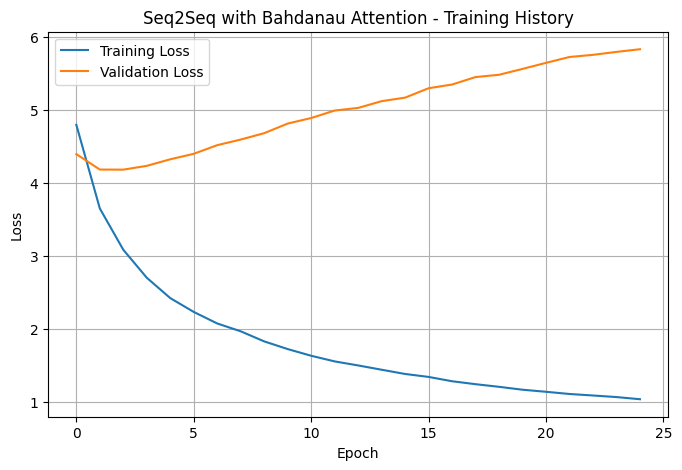

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Seq2Seq with Bahdanau Attention - Training History")
plt.legend()
plt.grid(True)
plt.show()

# Translation Inference

## Load Best Model

In [24]:
checkpoint = torch.load(
    "/kaggle/working/best_attention_model.pt",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best model loaded successfully!")

Best model loaded successfully!


## English-to-Bengali Translation Function

In [25]:
@torch.no_grad()
def translate(sentence, max_len=30):
    model.eval()

    # Preprocess English sentence
    sentence = clean_text(sentence, lowercase=True)
    tokens = sentence.split()

    # Convert tokens to indices
    src_indices = numericalize(tokens, en_stoi) + [EOS_IDX]
    src = torch.tensor([src_indices], device=device)

    # Encode source sentence
    encoder_outputs, hidden = model.encoder(src)
    mask = (src != PAD_IDX)

    # Start decoding
    input_token = torch.tensor([SOS_IDX], device=device)
    translated_tokens = []

    for _ in range(max_len):
        logits, hidden, _ = model.decoder(
            input_token, hidden, encoder_outputs, mask
        )

        predicted = logits.argmax(dim=1).item()

        if predicted == EOS_IDX:
            break

        if predicted not in (PAD_IDX, SOS_IDX):
            translated_tokens.append(bn_itos[predicted])

        input_token = torch.tensor([predicted], device=device)

    return " ".join(translated_tokens)

## Test Translations

In [26]:
samples = test_df.sample(5, random_state=SEED)

for _, row in samples.iterrows():
    prediction = translate(row["en"])

    print("English:   ", row["en"])
    print("Reference: ", row["bn"])
    print("Predicted: ", prediction)
    print("-" * 70)

English:    a snowboarder in gray pants and a white jacket catches some air .
Reference:  একজন লোক স্নোবোর্ডিং করছে
Predicted:  ধূসর প্যান্ট প্যান্ট পরা স্নোবোর্ডার সাদা জ্যাকেট এবং সাদা হাওয়ায় উড়ছে
----------------------------------------------------------------------
English:    the man in the red overalls stands on the sidewalk .
Reference:  লাল ওভারঅল পরা লোকটি ফুটপাতে দাঁড়িয়েছে
Predicted:  লাল হুডি পরা লোকটি ফুটপাতে দাঁড়িয়ে আছে
----------------------------------------------------------------------
English:    four people are walking on a bridge .
Reference:  একটি ব্রিজের উপর দিয়ে হাঁটছেন চার জন।
Predicted:  ব্রিজের উপর হাঁটছে
----------------------------------------------------------------------
English:    a small child on a blue toy is wearing an orange shirt .
Reference:  কমলা গেঞ্জি পড়া এক ছোট শিশু একটি নীল খেলনার উপর ।
Predicted:  একটি শিশু একটি কমলা রঙের কমলা রঙের জামা পরে আছে
----------------------------------------------------------------------
English:    a boy i

# BLEU Score Evaluation

## Calculate BLEU Score

In [27]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

# Reference Bengali translations
references = [
    [tokens] for tokens in test_df["bn_tokens"]
]

# Generate predictions for the test set
predictions = [
    translate(sentence).split()
    for sentence in tqdm(test_df["en"], desc="Evaluating")
]

# Calculate corpus BLEU
bleu = corpus_bleu(
    references,
    predictions,
    smoothing_function=SmoothingFunction().method1
)

print(f"Test BLEU Score: {bleu * 100:.2f}")

Evaluating:   0%|          | 0/3904 [00:00<?, ?it/s]

Test BLEU Score: 8.36


# Attention Visualization

## Translation with Attention Weights

In [28]:
@torch.no_grad()
def translate_with_attention(sentence, max_len=30):
    model.eval()

    # Preprocess and encode
    src_tokens = clean_text(sentence, lowercase=True).split() + ["<eos>"]
    src_indices = numericalize(src_tokens[:-1], en_stoi) + [EOS_IDX]
    src = torch.tensor([src_indices], device=device)

    encoder_outputs, hidden = model.encoder(src)
    mask = (src != PAD_IDX)

    input_token = torch.tensor([SOS_IDX], device=device)

    translated_tokens = []
    attention_list = []

    for _ in range(max_len):
        logits, hidden, weights = model.decoder(
            input_token, hidden, encoder_outputs, mask
        )

        predicted = logits.argmax(dim=1).item()

        if predicted == EOS_IDX:
            break

        if predicted not in (PAD_IDX, SOS_IDX):
            translated_tokens.append(bn_itos[predicted])
            attention_list.append(weights.squeeze(0).cpu())

        input_token = torch.tensor([predicted], device=device)

    attention_matrix = (
        torch.stack(attention_list).numpy()
        if attention_list else None
    )

    return src_tokens, translated_tokens, attention_matrix

## Plot Attention Heatmap

In [29]:
import plotly.graph_objects as go

sentence = test_df["en"].iloc[0]

src_tokens, translated_tokens, attention_matrix = translate_with_attention(sentence)

print("English:", sentence)
print("Bengali:", " ".join(translated_tokens))

if attention_matrix is not None:
    fig = go.Figure(data=go.Heatmap(
        z=attention_matrix,
        x=list(range(len(src_tokens))),
        y=list(range(len(translated_tokens))),
        colorscale="Blues",
        colorbar=dict(title="Attention Weight")
    ))

    fig.update_layout(
        title="Bahdanau Attention Heatmap",
        xaxis_title="English Tokens",
        yaxis_title="Generated Bengali Tokens",
        font=dict(family="Nirmala UI, Noto Sans Bengali, sans-serif"),
        width=1000,
        height=550
    )

    fig.update_xaxes(
        tickmode="array",
        tickvals=list(range(len(src_tokens))),
        ticktext=src_tokens,
        tickangle=-45
    )

    fig.update_yaxes(
        tickmode="array",
        tickvals=list(range(len(translated_tokens))),
        ticktext=translated_tokens,
        autorange="reversed"
    )

    fig.show()

English: a group of young people are watching a man on a dirt bike performing a stunt in the air .
Bengali: একদল লোক ডার্ট বাইকে চড়ে একটি স্টান্ট করছে


# Model Improvement

## Beam Search Translation

In [30]:
@torch.no_grad()
def beam_search_translate(sentence, beam_width=3, max_len=30):
    model.eval()

    tokens = clean_text(sentence, lowercase=True).split()
    indices = numericalize(tokens, en_stoi) + [EOS_IDX]
    src = torch.tensor([indices], device=device)

    encoder_outputs, hidden = model.encoder(src)
    mask = (src != PAD_IDX)

    beams = [([SOS_IDX], hidden, 0.0)]

    for _ in range(max_len):
        candidates = []

        for sequence, hidden, score in beams:
            if sequence[-1] == EOS_IDX:
                candidates.append((sequence, hidden, score))
                continue

            token = torch.tensor([sequence[-1]], device=device)

            logits, new_hidden, _ = model.decoder(
                token, hidden, encoder_outputs, mask
            )

            log_probs = torch.log_softmax(logits[0], dim=-1)
            log_probs[[PAD_IDX, SOS_IDX]] = float("-inf")

            values, indices = torch.topk(log_probs, beam_width)

            for value, idx in zip(values.tolist(), indices.tolist()):
                candidates.append((
                    sequence + [idx],
                    new_hidden,
                    score + value
                ))

        beams = sorted(
            candidates,
            key=lambda x: x[2] / (max(len(x[0]) - 1, 1) ** 0.7),
            reverse=True
        )[:beam_width]

        if all(seq[-1] == EOS_IDX for seq, _, _ in beams):
            break

    best_sequence = beams[0][0]

    result = [
        bn_itos[idx]
        for idx in best_sequence
        if idx not in (SOS_IDX, EOS_IDX, PAD_IDX)
    ]

    return " ".join(result)

## Compare Greedy vs. Beam Search

In [31]:
samples = test_df.sample(5, random_state=SEED)

for _, row in samples.iterrows():
    print("English:  ", row["en"])
    print("Reference:", row["bn"])
    print("Greedy:   ", translate(row["en"]))
    print("Beam:     ", beam_search_translate(row["en"]))
    print("-" * 70)

English:   a snowboarder in gray pants and a white jacket catches some air .
Reference: একজন লোক স্নোবোর্ডিং করছে
Greedy:    ধূসর প্যান্ট প্যান্ট পরা স্নোবোর্ডার সাদা জ্যাকেট এবং সাদা হাওয়ায় উড়ছে
Beam:      ধূসর প্যান্ট প্যান্ট এবং সাদা জ্যাকেট পরিহিত একজন স্নোবোর্ডার বাতাসে উড়ছে
----------------------------------------------------------------------
English:   the man in the red overalls stands on the sidewalk .
Reference: লাল ওভারঅল পরা লোকটি ফুটপাতে দাঁড়িয়েছে
Greedy:    লাল হুডি পরা লোকটি ফুটপাতে দাঁড়িয়ে আছে
Beam:      লাল জামা পরা লোকটি ফুটপাতে দাঁড়িয়ে আছে
----------------------------------------------------------------------
English:   four people are walking on a bridge .
Reference: একটি ব্রিজের উপর দিয়ে হাঁটছেন চার জন।
Greedy:    ব্রিজের উপর হাঁটছে
Beam:      চারজন মানুষ ব্রিজের উপর হাঁটছে
----------------------------------------------------------------------
English:   a small child on a blue toy is wearing an orange shirt .
Reference: কমলা গেঞ্জি পড়া এক ছোট শিশু একট

## Beam Search BLEU Evaluation

In [32]:
# Generate beam search predictions
beam_predictions = [
    beam_search_translate(sentence).split()
    for sentence in tqdm(test_df["en"], desc="Beam Search")
]

# Calculate BLEU
beam_bleu = corpus_bleu(
    references,
    beam_predictions,
    smoothing_function=SmoothingFunction().method1
)

print(f"Greedy Search BLEU: {bleu * 100:.2f}")
print(f"Beam Search BLEU:   {beam_bleu * 100:.2f}")
print(f"BLEU Difference:    {(beam_bleu - bleu) * 100:+.2f}")

Beam Search:   0%|          | 0/3904 [00:00<?, ?it/s]

Greedy Search BLEU: 8.36
Beam Search BLEU:   9.50
BLEU Difference:    +1.13


# Improve Training & Reduce Overfitting

## Initialize a Fresh Model

In [33]:
# Fresh model initialization
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

encoder = Encoder(len(en_stoi), EMBED_DIM, HIDDEN_DIM)
attention = BahdanauAttention(HIDDEN_DIM)
decoder = Decoder(len(bn_stoi), EMBED_DIM, HIDDEN_DIM, attention)

model = Seq2Seq(encoder, decoder).to(device)

optimizer = optim.Adam(model.parameters(), lr=0.001)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

EPOCHS = 25
PATIENCE = 5
CLIP = 1.0

## Improved Validation Function

In [34]:
@torch.no_grad()
def validate_epoch(model, loader):
    model.eval()
    total_loss = 0

    for src, tgt in loader:
        src, tgt = src.to(device), tgt.to(device)

        outputs = model(src, tgt, teacher_forcing_ratio=1.0)

        loss = criterion(
            outputs.reshape(-1, outputs.size(-1)),
            tgt[:, 1:].reshape(-1)
        )

        total_loss += loss.item()

    return total_loss / len(loader)

## Training with Early Stopping

In [35]:
train_losses = []
val_losses = []

best_val_loss = float("inf")
patience_counter = 0

for epoch in range(EPOCHS):
    train_loss = train_epoch(model, train_loader)
    val_loss = validate_epoch(model, val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    scheduler.step(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "en_stoi": en_stoi,
            "bn_stoi": bn_stoi,
            "embed_dim": EMBED_DIM,
            "hidden_dim": HIDDEN_DIM
        }, "/kaggle/working/improved_attention_model.pt")

    else:
        patience_counter += 1

    lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train: {train_loss:.4f} | "
        f"Val: {val_loss:.4f} | "
        f"LR: {lr:.6f}"
    )

    if patience_counter >= PATIENCE:
        print(f"Early stopping at epoch {epoch+1}")
        break

# Restore best model
checkpoint = torch.load(
    "/kaggle/working/improved_attention_model.pt",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(f"\nBest Validation Loss: {best_val_loss:.4f}")

Training:   0%|          | 0/488 [00:00<?, ?it/s]

Epoch 1/25 | Train: 4.8007 | Val: 3.5869 | LR: 0.001000


Training:   0%|          | 0/488 [00:00<?, ?it/s]

Epoch 2/25 | Train: 3.6483 | Val: 3.1968 | LR: 0.001000


Training:   0%|          | 0/488 [00:00<?, ?it/s]

Epoch 3/25 | Train: 3.0962 | Val: 3.0700 | LR: 0.001000


... (8 outputs left out)

Training:   0%|          | 0/488 [00:00<?, ?it/s]

Epoch 8/25 | Train: 1.8155 | Val: 3.0858 | LR: 0.000500


Training:   0%|          | 0/488 [00:00<?, ?it/s]

Epoch 9/25 | Train: 1.6561 | Val: 3.1009 | LR: 0.000500
Early stopping at epoch 9

Best Validation Loss: 3.0361


## Visualize Training History

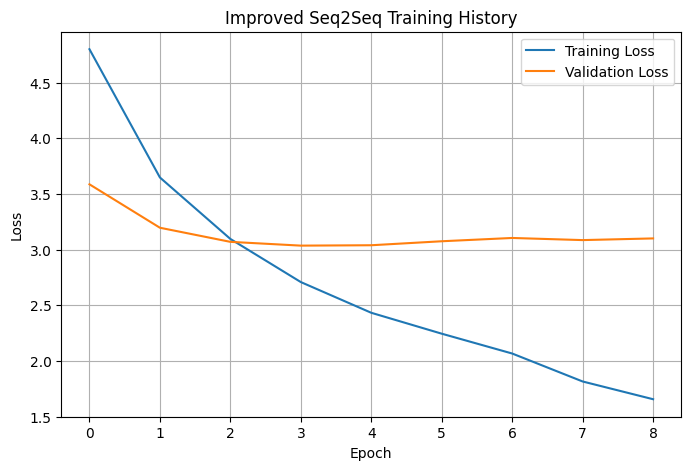

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Improved Seq2Seq Training History")
plt.legend()
plt.grid(True)
plt.show()

# Evaluate Improved Model

## Compare Original vs. Improved Model

In [37]:
val_references = [[tokens] for tokens in val_df["bn_tokens"]]

checkpoints = {
    "Original": "/kaggle/working/best_attention_model.pt",
    "Improved": "/kaggle/working/improved_attention_model.pt"
}

results = {}

for name, path in checkpoints.items():
    checkpoint = torch.load(path, map_location=device, weights_only=True)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    for method, translate_fn in [
        ("Greedy", translate),
        ("Beam", beam_search_translate)
    ]:
        predictions = [
            translate_fn(sentence).split()
            for sentence in tqdm(val_df["en"], desc=f"{name} - {method}")
        ]

        score = corpus_bleu(
            val_references,
            predictions,
            smoothing_function=SmoothingFunction().method1
        ) * 100

        results[(name, method)] = score

# Restore improved model
checkpoint = torch.load(
    checkpoints["Improved"], map_location=device, weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("\nValidation BLEU Comparison")
for (name, method), score in results.items():
    print(f"{name:10} | {method:6} | BLEU: {score:.2f}")


Original - Greedy:   0%|          | 0/3904 [00:00<?, ?it/s]

Original - Beam:   0%|          | 0/3904 [00:00<?, ?it/s]

Improved - Greedy:   0%|          | 0/3904 [00:00<?, ?it/s]

Improved - Beam:   0%|          | 0/3904 [00:00<?, ?it/s]


Validation BLEU Comparison
Original   | Greedy | BLEU: 8.47
Original   | Beam   | BLEU: 9.75
Improved   | Greedy | BLEU: 8.87
Improved   | Beam   | BLEU: 9.96


## Visualize BLEU Comparison

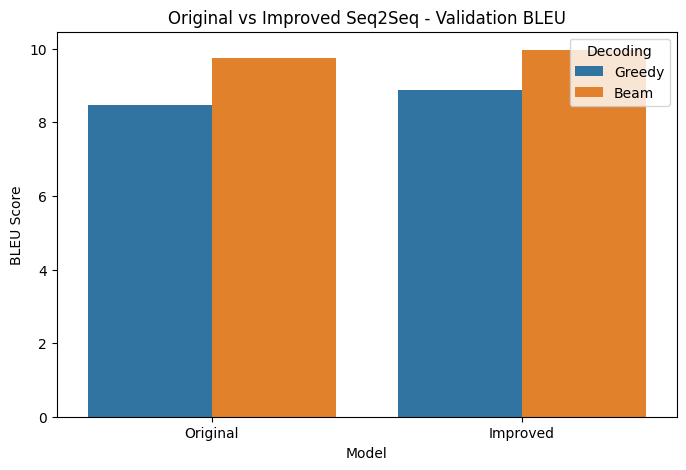

In [38]:
comparison_df = pd.DataFrame([
    {"Model": name, "Decoding": method, "BLEU": score}
    for (name, method), score in results.items()
])

plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="BLEU",
    hue="Decoding"
)

plt.title("Original vs Improved Seq2Seq - Validation BLEU")
plt.ylabel("BLEU Score")
plt.xlabel("Model")
plt.show()

# Final Evaluation

In [39]:
model.eval()

final_predictions = [
    beam_search_translate(sentence).split()
    for sentence in tqdm(test_df["en"], desc="Final Test")
]

final_bleu = corpus_bleu(
    references,
    final_predictions
) * 100

print(f"Improved Model Test BLEU: {final_bleu:.2f}")

Final Test:   0%|          | 0/3904 [00:00<?, ?it/s]

Improved Model Test BLEU: 8.87
